In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
from src.data_loader import download_stock_data
from src.data_cleaning import clean_stock_data
from src.features import add_features

raw = download_stock_data("AAPL")
df = clean_stock_data(raw, "AAPL")
data = add_features(df)

print(data.shape)
data.head()

(2909, 23)


Price,Open,High,Low,Close,Adj Close,Volume,ret_1,ret_lag_1,ret_lag_2,ret_lag_3,...,sma_10_ratio,sma_20_ratio,sma_50_ratio,vol_10,vol_30,rsi_14,macd,vol_chg,target_ret,target_dir
Date,,,,,,,,,,,,,,,,,,,,,
2015-03-16,30.969999,31.237499,30.717501,31.237499,27.734200,143497200,0.011004,-0.006911,0.018079,-0.018231,...,-0.006591,-0.021619,0.045988,0.012886,0.013000,32.710620,0.007758,-0.307811,0.016727,1
2015-03-17,31.475000,31.830000,31.412500,31.760000,28.198105,204092400,0.016727,0.011004,-0.006911,0.018079,...,0.011892,-0.004946,0.060264,0.014304,0.013135,45.533398,0.007959,0.422274,0.011256,1
2015-03-18,31.750000,32.290001,31.592501,32.117500,28.515511,261083600,0.011256,0.016727,0.011004,-0.006911,...,0.023339,0.006353,0.068163,0.014748,0.013223,44.971657,0.008923,0.279242,-0.007550,0
2015-03-19,32.187500,32.312500,31.850000,31.875000,28.300213,183238000,-0.007550,0.011256,0.016727,0.011004,...,0.014732,-0.000874,0.056294,0.013868,0.013324,47.391270,0.009113,-0.298164,-0.012549,0
2015-03-20,32.062500,32.099998,31.290001,31.475000,27.945068,274780400,-0.012549,-0.007550,0.011256,0.016727,...,0.002556,-0.012018,0.039838,0.014503,0.013563,41.765640,0.008206,0.499582,0.010405,1


In [2]:
train = data[:"2021-12-31"]
val   = data["2022-01-01":"2023-12-31"]
test  = data["2024-01-01":]

print(len(train), len(val), len(test))

1714 501 694


In [3]:
y = test["target_ret"]   # tomorrow's real return

def report(name, pred):
    mae  = (y - pred).abs().mean()
    rmse = np.sqrt(((y - pred) ** 2).mean())
    acc  = ((pred > 0) == (y > 0)).mean()
    print(f"{name:22s} MAE={mae:.5f}  RMSE={rmse:.5f}  Up/Down accuracy={acc:.3f}")

report("Always predict 0", pd.Series(0.0, index=y.index))
report("Train average", pd.Series(train["target_ret"].mean(), index=y.index))
report("Same as today", test["ret_1"])
print("Always say UP accuracy:", (y > 0).mean().round(3))

Always predict 0       MAE=0.01171  RMSE=0.01732  Up/Down accuracy=0.458
Train average          MAE=0.01165  RMSE=0.01729  Up/Down accuracy=0.542
Same as today          MAE=0.01646  RMSE=0.02400  Up/Down accuracy=0.509
Always say UP accuracy: 0.542


In [5]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in data.columns
                if c.startswith(("ret_", "sma_", "vol_", "rsi", "macd"))]

scaler = StandardScaler().fit(train[feature_cols])
model = Ridge(alpha=1.0).fit(scaler.transform(train[feature_cols]), train["target_ret"])

pred = pd.Series(model.predict(scaler.transform(test[feature_cols])), index=test.index)
report("Ridge", pred)

Ridge                  MAE=0.01188  RMSE=0.01751  Up/Down accuracy=0.490


In [6]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
)
rf.fit(train[feature_cols], train["target_ret"])

pred_rf = pd.Series(rf.predict(test[feature_cols]), index=test.index)
report("Random Forest", pred_rf)

Random Forest          MAE=0.01171  RMSE=0.01735  Up/Down accuracy=0.520


In [7]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    n_estimators=200,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    random_state=42,
)
gb.fit(train[feature_cols], train["target_ret"])

pred_gb = pd.Series(gb.predict(test[feature_cols]), index=test.index)
report("Gradient Boosting", pred_gb)

Gradient Boosting      MAE=0.01188  RMSE=0.01758  Up/Down accuracy=0.532


In [8]:
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(imp.head(8))

sma_5_ratio     0.148733
ret_1           0.117515
sma_10_ratio    0.096250
vol_10          0.083229
ret_lag_5       0.082606
sma_20_ratio    0.071123
ret_lag_3       0.059277
rsi_14          0.053879
dtype: float64


In [9]:
from sklearn.ensemble import RandomForestRegressor

feature_cols = [c for c in data.columns
                if c.startswith(("ret_", "sma_", "vol_", "rsi", "macd"))]

years = sorted(set(data.index.year))
rows = []

for test_year in years[-4:]:                      # last 4 years, one at a time
    tr = data[data.index.year < test_year]        # everything before that year
    te = data[data.index.year == test_year]       # that year only

    m = RandomForestRegressor(n_estimators=200, max_depth=4,
                              min_samples_leaf=20, random_state=42, n_jobs=-1)
    m.fit(tr[feature_cols], tr["target_ret"])
    p = m.predict(te[feature_cols])

    rows.append({
        "year": test_year,
        "model_acc": ((p > 0) == (te["target_ret"] > 0)).mean(),
        "always_up_acc": (te["target_ret"] > 0).mean(),
        "model_mae": (te["target_ret"] - p).abs().mean(),
        "avg_mae": (te["target_ret"] - tr["target_ret"].mean()).abs().mean(),
    })

result = pd.DataFrame(rows).set_index("year").round(4)
print(result)
print(result.mean().round(4))

      model_acc  always_up_acc  model_mae  avg_mae
year                                              
2023     0.5160         0.5600     0.0098   0.0098
2024     0.5397         0.5635     0.0103   0.0103
2025     0.5080         0.5240     0.0127   0.0127
2026     0.5417         0.5365     0.0121   0.0121
model_acc        0.5264
always_up_acc    0.5460
model_mae        0.0112
avg_mae          0.0112
dtype: float64


Final value of $1:
strategy    1.85
buy_hold    2.75
Name: 2026-10-07 00:00:00, dtype: float64
Share of days in the market: 0.619
Number of trades: 215


<Axes: title={'center': 'Growth of $1: model vs buy and hold'}, xlabel='Date'>

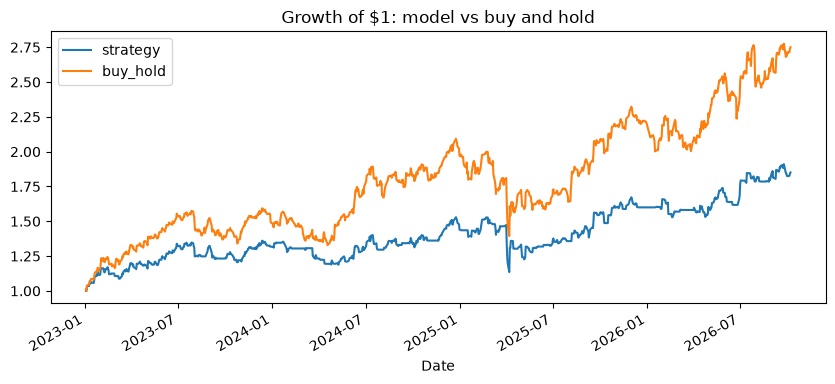

In [10]:
all_rows = []

for test_year in years[-4:]:
    tr = data[data.index.year < test_year]
    te = data[data.index.year == test_year]

    m = RandomForestRegressor(n_estimators=200, max_depth=4,
                              min_samples_leaf=20, random_state=42, n_jobs=-1)
    m.fit(tr[feature_cols], tr["target_ret"])
    p = pd.Series(m.predict(te[feature_cols]), index=te.index)

    signal = (p > tr["target_ret"].mean()).astype(int)   # 1 = hold, 0 = cash
    all_rows.append(pd.DataFrame({"signal": signal, "ret": te["target_ret"]}))

bt = pd.concat(all_rows)

cost = 0.001
trades = bt["signal"].diff().abs().fillna(0)
bt["strategy"] = bt["signal"] * bt["ret"] - trades * cost
bt["buy_hold"] = bt["ret"]

growth = (1 + bt[["strategy", "buy_hold"]]).cumprod()

print("Final value of $1:")
print(growth.iloc[-1].round(3))
print("Share of days in the market:", bt["signal"].mean().round(3))
print("Number of trades:", int(trades.sum()))

growth.plot(figsize=(10, 4), title="Growth of $1: model vs buy and hold")

In [11]:
bt["strategy_nofee"] = bt["signal"] * bt["ret"]
print((1 + bt[["strategy_nofee", "strategy", "buy_hold"]]).cumprod().iloc[-1].round(3))

strategy_nofee    2.294
strategy          1.850
buy_hold          2.750
Name: 2026-10-07 00:00:00, dtype: float64
